<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

## Folder placement

Current location: `analyses/calibration/quality_params/`

## 1) Data used

Describe the empirical data source(s) in enough detail for a future reader to obtain or reproduce it.

- **Dataset name or source**: COVID-19 data from SUPSI
- **Time range**: `2021-03-01` to `2021-03-31`
- **Access / documentation link**: Data has been collected with Twitter API, NewsGuard has been used to get the ratings. Data can be requested by contacting [Gianluca Nogara](https://gi-ux.github.io/)
- **Raw files / tables used**: tweets_calibrated_cleaned.parquet contains id, user_id, created_at, urls
- **Preprocessing steps**: 
   1. Remove tweets without classifiable domains
   2. Obtain the score from NewsGuard
   3. Exclude satira and potentially misinterpretable data
   4. Calculate the average score for user
- **Notes / limitations**: Data has been collected using the old Twitter API


In [1]:
import pandas as pd
import ast
from urllib.parse import urlparse
import numpy as np

print("Loading data...")
base = ''
data_path = base + "tweets_calibrated_cleaned.parquet"
file_path = base + 'newsguard_ratings.csv'
df = pd.read_parquet(data_path, engine='fastparquet')
df

Loading data...


,id,user_id,created_at,urls
0,1366438606429184001,2335424845,2021-03-01,"[{'url': 'https://t.co/W7vhUYudTp', 'expanded_..."
1,1366438599575687171,222207235,2021-03-01,"[{'url': 'https://t.co/sibepIOsHy', 'expanded_..."
2,1366438604990414849,825558208425062402,2021-03-01,"[{'url': 'https://t.co/wniKe1j6V7', 'expanded_..."
3,1366438605548314626,23444722,2021-03-01,"[{'url': 'https://t.co/1NMWWVgAri', 'expanded_..."
4,1366438606227709954,1076733241715900417,2021-03-01,"[{'url': 'https://t.co/5Qp907sJHv', 'expanded_..."
...,...,...,...,...
20944234,1377192688294850561,1067939172537708544,2021-03-31,"[{'url': 'https://t.co/X1NTsJq1nI', 'expanded_..."
20944235,1377192676236406790,1237803190583799811,2021-03-31,"[{'url': 'https://t.co/1JY83O7CAA', 'expanded_..."
20944236,1377192679566684160,138616820,2021-03-31,"[{'url': 'https://t.co/rOH9fsCEVG', 'expanded_..."
20944237,1377192678568439810,760860875242610688,2021-03-31,"[{'url': 'https://t.co/j9niY5uJcT', 'expanded_..."


In [2]:
# Provide script used to prepare the data.
newsguard = pd.read_csv(file_path, lineterminator='\n', low_memory=False, encoding='utf-8')

# Remove satire from NewsGuard and obtain the list of domains from tweets
def clean_up(df, newsguard):
    newsguard = newsguard.rename(columns={'identifier': 'domain'})
    newsguard = newsguard[['domain', 'rank', 'score']]
    newsguard = newsguard[newsguard['rank']!= 'S']
    df['urls'] = df['urls'].apply(lambda x: ast.literal_eval(x)[0]['expanded_url'] if pd.notnull(x) else None)
    df['urls'] = df['urls'].apply(lambda x: urlparse(x).netloc.replace('www.', '') if pd.notnull(x) else None)
    df.rename(columns={'urls': 'domain'}, inplace=True)
    return df, newsguard
# merge datasets
def transform(df, newsguard):
    df_merge = pd.merge(df, newsguard[['domain', 'score']], on='domain', how='left')
    df_merge = df_merge[df_merge['score'].notna()]
    return df_merge

df, newsguard = clean_up(df, newsguard)
df_merge = transform(df, newsguard)
df_merge

,id,user_id,created_at,domain,score
4,1366438606227709954,1076733241715900417,2021-03-01,nationalgeographic.com,100.0
9,1366438594441736193,1462504146,2021-03-01,theguardian.com,100.0
11,1366438594974535683,940217378876674048,2021-03-01,pscp.tv,0.0
20,1366438608698286084,1066062101498740736,2021-03-01,washingtonpost.com,100.0
21,1366438608698286084,1066062101498740736,2021-03-01,washingtonpost.com,100.0
...,...,...,...,...,...
21993456,1377192669751939078,772914588568395780,2021-03-31,factcheck.org,100.0
21993459,1377192670699921409,1333883500924121092,2021-03-31,welt.de,82.0
21993460,1377192673396760578,1330667748,2021-03-31,newscientist.com,92.5
21993467,1377192681223294976,2699284032,2021-03-31,theguardian.com,100.0


## 2) New feature contribution

Explain what new feature this calibration adds and where it lives in the codebase.

- **Component**: `Message`
- **What it adds**: Function to generate the quality based on one parameter
- **Code location**: `libs/simsom/message.py`
- **Design rationale**: This approach is simple and flexible: with a single parameter, we can generate a realistic binomial distribution


## 2b) References & provenance

Make the calibration traceable to specific code and design. Complete one or more of items below.



## 3) Analysis / calibration method

Document how you transform the data into model parameters or behaviors.

- **Features extracted**: From URLS shared by the users, we extracted the distribution of the NewsGuard score
- **Estimation / fitting**: Each scenario could result in a slightly different distribution in terms of slope and the curve toward 0 (low-quality); we only retain the slope of the high-quality component and use a parameter that acts as a mixer; in the default scenario, the curve is exclusively high-quality
- **Validation**: We were able to replicate Bao’s plot (S3), which, using different data, yielded a value similar to ours. We therefore generated a parameterized binomial distribution capable of replicating Bao’s data and, by adjusting the parameter, replicating the COVID-19 SUPSI dataset and the VaccinItaly dataset.  


In [4]:
# get the average quality per user and his variance across the posts
avg_var = df_merge.groupby('user_id')['score'].agg(['mean'])
avg_var.reset_index(inplace=True)
avg_var.rename(columns={'mean': 'avg_quality'}, inplace=True)
avg_var = avg_var[avg_var['avg_quality'].notna()]
avg_var

,user_id,avg_quality
0,22,100.0
1,221,100.0
2,246,100.0
3,259,100.0
4,293,100.0
...,...,...
878492,1377359127840649216,95.0
878493,1377370840128425984,80.0
878494,1377378733284159489,0.0
878495,1377379399260078081,0.0


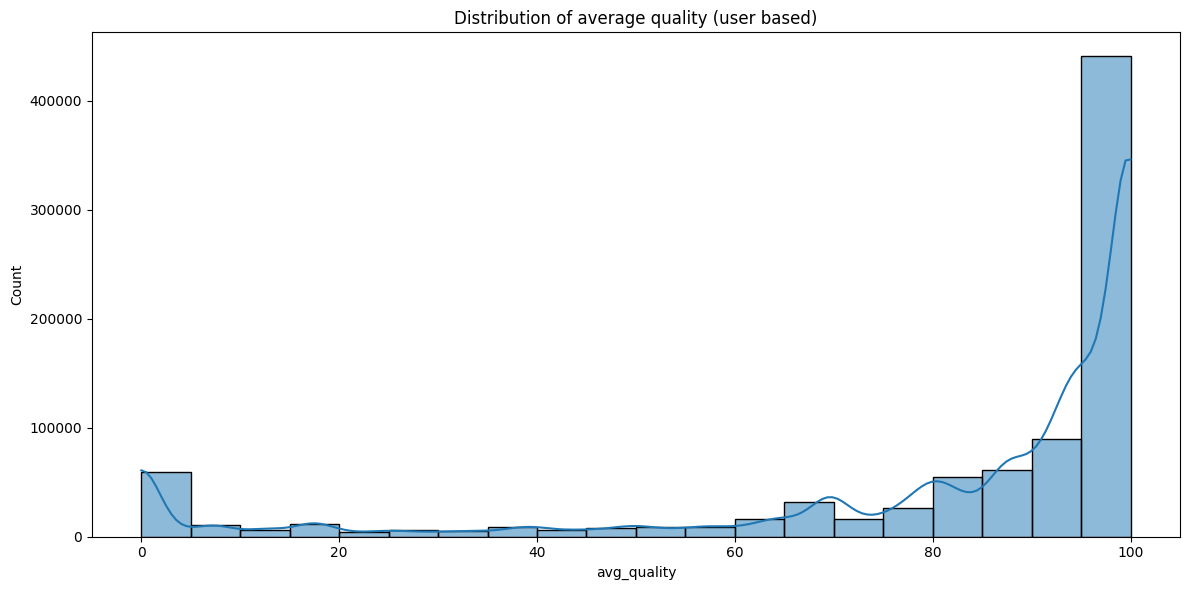

In [5]:
# plot the distriubution of the average quality and the variance
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 6))
sns.histplot(avg_var['avg_quality'], bins=20, kde=True)
plt.title('Distribution of average quality (user based)')
plt.tight_layout()
plt.show()

In [6]:
# remove the low-quality components and calculate the empirical lambda
authentic_quality = avg_var[avg_var['avg_quality'] > 50]['avg_quality']

# the empiric lambda is the reciprocal of the average distance from the top (100) for the authentic users
mean_distance = np.mean(100 - authentic_quality)
empiric_lambda = 1 / mean_distance

print(f"Average distance from the top: {mean_distance:.2f}")
print(f"Estimated slope (lambda): {empiric_lambda:.4f}")

Average distance from the top: 8.40
Estimated slope (lambda): 0.1190


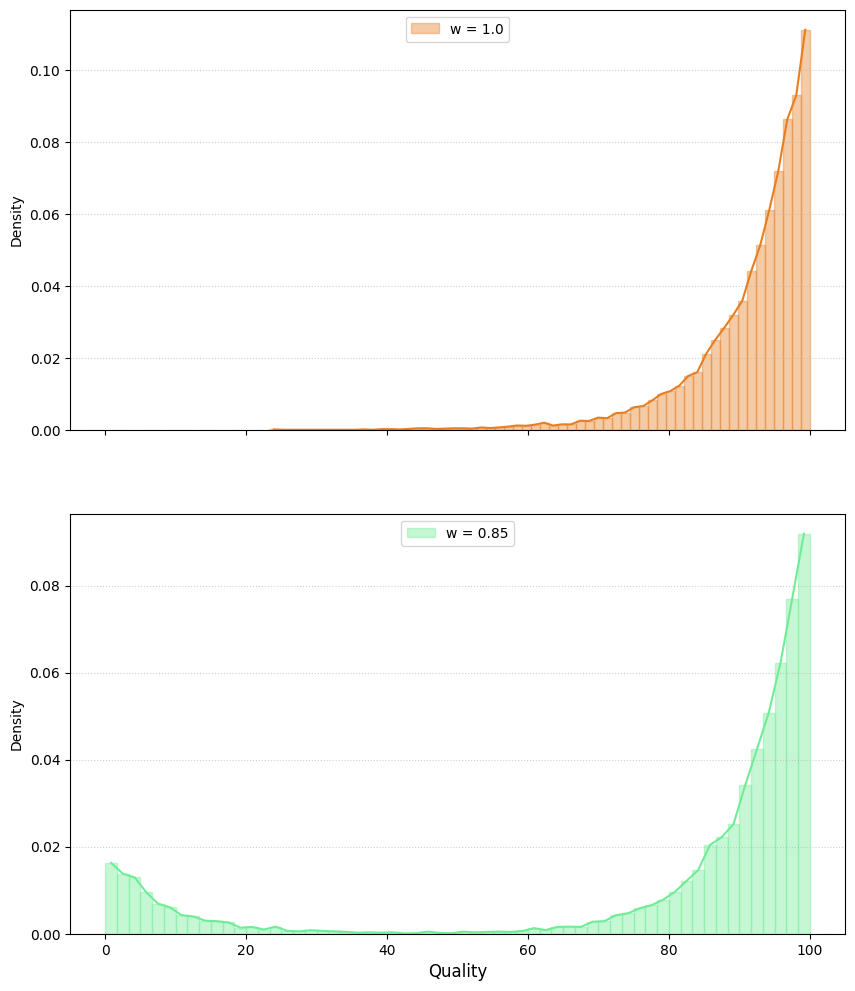

In [11]:
LAMBDA = empiric_lambda
N_SAMPLES = 10000 

def generate_quality(w):
    """Generate a quality value in [0, 100] using Inverse Transform Sampling"""
    if np.random.rand() < w:
        # High Quality Cluster
        u = np.random.rand()
        val = 100 + (1/LAMBDA) * np.log(1 - u * (1 - np.exp(-100 * LAMBDA)))
    else:
        # Low Quality Cluster
        u = np.random.rand()
        val = -(1/LAMBDA) * np.log(1 - u * (1 - np.exp(-100 * LAMBDA)))
    return val

scenarios = [
    ("Baseline (Bao)", 1.0, '#e67e22'),
    ("COVID data", 0.85, "#70ec97"),
]

# plots
fig, axes = plt.subplots(2, 1, figsize=(10, 12), sharex=True)

for i, (title, w_val, color) in enumerate(scenarios):
    data = [generate_quality(w_val) for _ in range(N_SAMPLES)]
    ax = axes[i]
    counts, bins, _ = ax.hist(data, bins=60, density=True, alpha=0.4, 
                            color=color, edgecolor=color, label=f"w = {w_val}")
    ax.plot(bins[:-1] + np.diff(bins)/2, counts, color=color, lw=1.5)
    ax.set_ylabel("Density", fontsize=10)
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.legend(loc='upper center')
axes[1].set_xlabel("Quality", fontsize=12)
plt.show()

## 3b) Reproduction steps

Provide minimal steps so a new researcher can reproduce the analysis.

1. Ensure paths are correct
2. Run the notebook top-to-bottom to reproduce the plots anhd fitted params


## 4) Results

Summarize the outcome and attach key plots/tables. If large, don't upload to repo.

- **Outputs / artifacts**: Parameter and function for quality
- **Where results are saved**: config files
- **Key takeaways**: quality can be modulated using a bi-exponential distribution with fixed slope and one parameter to modulate the two curves


## 5) Change log

Record updates so future changes are traceable.

- `2026-03-27`: Obtained the results
